BÀI 4. MLP CHO DỮ LIỆU ẢNH FASHION-MNIST

In [17]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "reportlab"], check=False)

import os, random, time, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
DEVICE = "GPU" if gpus else "CPU"
print("TensorFlow version:", tf.__version__)
print("GPU available:", gpus)
print("Random seed =", SEED)

TensorFlow version: 2.21.0
GPU available: []
Random seed = 42


In [18]:
import os, datetime, collections
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

from reportlab.lib.pagesizes import A4
from reportlab.lib.units import cm as CM
from reportlab.lib import colors
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib.enums import TA_CENTER, TA_JUSTIFY
from reportlab.lib.utils import ImageReader
from reportlab.platypus import (SimpleDocTemplate, Paragraph, Spacer, Table,
                                TableStyle, Image, PageBreak, KeepTogether)
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont

FIG_DIR = "report_figs"
os.makedirs(FIG_DIR, exist_ok=True)

# ---------------------------------------------------------------- tiện ích định dạng
def vn(x, d=2):
    """Số thập phân kiểu Việt Nam (dấu phẩy)."""
    return f"{x:.{d}f}".replace(".", ",")

def vni(n):
    """Số nguyên có dấu chấm ngăn cách hàng nghìn."""
    return f"{int(n):,}".replace(",", ".")

def pct(x, d=2):
    return vn(100 * x, d)

def lrs(x):
    """Learning rate dạng 0,001."""
    return f"{x:g}".replace(".", ",")

def dir_word(delta, eps=0.005):
    return "không đổi" if abs(delta) < eps else ("tăng" if delta > 0 else "giảm")

def change_text(delta_pp):
    """Mô tả thay đổi theo điểm phần trăm."""
    w = dir_word(delta_pp)
    if w == "không đổi":
        return "không đổi"
    return f"{w} {vn(abs(delta_pp))} điểm phần trăm"

def best_idx(results, key, mode="max"):
    vals = [r[key] for r in results]
    return int(np.argmax(vals) if mode == "max" else np.argmin(vals))

# ---------------------------------------------------------------- hình vẽ
def plot_compare(results, labels, title, fname):
    """Vẽ loss và accuracy (train: nét đứt, val: nét liền) cho nhiều lần chạy."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    cmap = plt.get_cmap("tab10")
    for i, (r, lb) in enumerate(zip(results, labels)):
        h = r["hist"]
        ep = np.arange(1, len(h["loss"]) + 1)
        c = cmap(i)
        axes[0].plot(ep, h["loss"], "--", color=c, label=f"{lb} - train")
        axes[0].plot(ep, h["val_loss"], "-", color=c, label=f"{lb} - val")
        axes[0].plot(r["best_epoch"], h["val_loss"][r["best_epoch"] - 1], "o", color=c)
        axes[1].plot(ep, h["accuracy"], "--", color=c, label=f"{lb} - train")
        axes[1].plot(ep, h["val_accuracy"], "-", color=c, label=f"{lb} - val")
        axes[1].plot(r["best_epoch"], h["val_accuracy"][r["best_epoch"] - 1], "o", color=c)
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
    axes[0].set_title("Loss"); axes[1].set_title("Accuracy")
    for ax in axes:
        ax.grid(alpha=0.3)
    axes[1].legend(fontsize=7, loc="lower right")
    fig.suptitle(title)
    fig.tight_layout()
    path = os.path.join(FIG_DIR, fname)
    fig.savefig(path, dpi=150)
    return fig, path

def plot_top_errors(order, X, y_true, y_pred, conf, names, fname):
    fig, axes = plt.subplots(4, 5, figsize=(11, 10))
    for rank, (idx, ax) in enumerate(zip(order, axes.ravel()), start=1):
        ax.imshow(X[idx], cmap="gray")
        ax.set_title(f"{rank}. Ảnh {idx} · {conf[idx]*100:.2f}%\n"
                     f"{names[y_true[idx]]} → {names[y_pred[idx]]}", fontsize=8)
        ax.axis("off")
    for ax in axes.ravel()[len(order):]:
        ax.axis("off")
    fig.tight_layout()
    path = os.path.join(FIG_DIR, fname)
    fig.savefig(path, dpi=150)
    return fig, path

def plot_confusion(cm, names, fname):
    from sklearn.metrics import ConfusionMatrixDisplay
    fig, ax = plt.subplots(figsize=(8, 8))
    ConfusionMatrixDisplay(cm, display_labels=names).plot(
        ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
    ax.set_title("Confusion matrix (tập test)")
    fig.tight_layout()
    path = os.path.join(FIG_DIR, fname)
    fig.savefig(path, dpi=150)
    return fig, path

# ---------------------------------------------------------------- phân tích tự động
def confused_pairs(cm, names, top=2):
    pairs = []
    n = cm.shape[0]
    for i in range(n):
        for j in range(i + 1, n):
            pairs.append((int(cm[i, j] + cm[j, i]), names[i], names[j]))
    pairs.sort(reverse=True)
    return pairs[:top]

REASONS = {
    frozenset(["T-shirt/top", "Shirt"]): "hai loại áo có dáng thân và tay gần giống nhau, chỉ khác ở chi tiết cổ và hàng cúc",
    frozenset(["Pullover", "Coat"]): "đều là áo tay dài che thân, khác nhau chủ yếu ở độ dài và chi tiết khóa/cúc",
    frozenset(["Pullover", "Shirt"]): "đều là áo tay dài có hình dạng tổng thể tương tự",
    frozenset(["Coat", "Shirt"]): "đều là áo tay dài, khác nhau ở chi tiết nhỏ mà MLP khó nắm bắt",
    frozenset(["Trouser", "Dress"]): "dáng dọc, hẹp ở trên, rộng dần xuống dưới nên dễ bị nhầm",
    frozenset(["T-shirt/top", "Dress"]): "dáng áo dài hoặc váy ngắn có đường viền gần với áo thun",
    frozenset(["Dress", "Coat"]): "dáng dài, đường viền tổng thể gần nhau",
    frozenset(["Sneaker", "Sandal"]): "đều là giày thấp, khác nhau ở độ kín của thân giày",
    frozenset(["Sneaker", "Ankle boot"]): "đều là giày có đế rõ, khác nhau ở độ cao cổ giày",
    frozenset(["Sandal", "Ankle boot"]): "đều có đế và gót, khác nhau ở độ kín của thân giày",
    frozenset(["Bag", "Sandal"]): "ảnh có nhiều chi tiết nhỏ, không có hình dạng điển hình",
    frozenset(["Bag", "Sneaker"]): "hình khối nằm ngang gần với giày",
    frozenset(["T-shirt/top", "Bag"]): "ảnh có hình khối vuông với nhiều chi tiết",
    frozenset(["Bag", "Shirt"]): "ảnh có hình khối vuông với nhiều chi tiết",
}
DEFAULT_REASON = ("hình dạng tổng thể và độ tương phản của hai lớp gần nhau; MLP làm phẳng ảnh nên "
                  "không khai thác được cấu trúc không gian")

def analyse_fit(res):
    """Nhận xét underfitting/overfitting từ learning curve của một lần chạy."""
    h, b, n = res["hist"], res["best_epoch"] - 1, len(res["hist"]["loss"])
    tr_acc, va_acc = h["accuracy"][b], h["val_accuracy"][b]
    gap = (tr_acc - va_acc) * 100
    out = []
    out.append(f"Tại epoch tốt nhất ({res['best_epoch']}/{n}), train accuracy là {pct(tr_acc)}%, "
               f"validation accuracy là {pct(va_acc)}%, chênh lệch {vn(gap)} điểm phần trăm.")
    if n > res["best_epoch"] and h["loss"][-1] < h["loss"][b] and h["val_loss"][-1] > h["val_loss"][b]:
        sev = "nhẹ" if gap < 3 else "đáng kể"
        out.append(f"Từ epoch {res['best_epoch']} đến epoch {n}, train loss giảm từ {vn(h['loss'][b], 4)} "
                   f"xuống {vn(h['loss'][-1], 4)} trong khi validation loss tăng từ {vn(h['val_loss'][b], 4)} "
                   f"lên {vn(h['val_loss'][-1], 4)}. Đây là dấu hiệu overfitting {sev}; "
                   f"EarlyStopping dừng huấn luyện và khôi phục trọng số tại epoch {res['best_epoch']}.")
    else:
        out.append("Chưa thấy validation loss tăng rõ rệt trong khi train loss tiếp tục giảm, "
                   "nên chưa có dấu hiệu overfitting rõ ràng trong lần chạy này.")
    if tr_acc < 0.85 and gap < 2:
        out.append("Train accuracy còn thấp và gần validation accuracy, có thể mô hình chưa đủ khả năng biểu diễn (underfitting).")
    else:
        out.append("Train accuracy không thấp bất thường, chưa thấy dấu hiệu underfitting rõ.")
    return out

def n_increases(vals):
    return int(sum(1 for a, b in zip(vals[:-1], vals[1:]) if b > a))

# ---------------------------------------------------------------- dựng PDF
def build_report(R, info, class_names, cm, report_dict, top_order, top_conf, y_test, y_pred,
                 fig_paths, out_path, device, tf_version, seed, extra_notes=""):
    fdir = os.path.join(matplotlib.get_data_path(), "fonts", "ttf")
    pdfmetrics.registerFont(TTFont("DV", os.path.join(fdir, "DejaVuSans.ttf")))
    pdfmetrics.registerFont(TTFont("DV-B", os.path.join(fdir, "DejaVuSans-Bold.ttf")))
    pdfmetrics.registerFont(TTFont("DV-I", os.path.join(fdir, "DejaVuSans-Oblique.ttf")))
    pdfmetrics.registerFont(TTFont("DV-BI", os.path.join(fdir, "DejaVuSans-BoldOblique.ttf")))
    pdfmetrics.registerFontFamily("DV", normal="DV", bold="DV-B", italic="DV-I", boldItalic="DV-BI")

    TEAL = colors.HexColor("#134B5F")
    LIGHT = colors.HexColor("#F1F5F8")
    st = dict(
        body=ParagraphStyle("body", fontName="DV", fontSize=10, leading=15, alignment=TA_JUSTIFY, spaceAfter=5),
        h1=ParagraphStyle("h1", fontName="DV-B", fontSize=16, leading=21, textColor=TEAL, spaceBefore=6, spaceAfter=8),
        h2=ParagraphStyle("h2", fontName="DV-B", fontSize=12, leading=16, textColor=TEAL, spaceBefore=8, spaceAfter=5),
        cap=ParagraphStyle("cap", fontName="DV", fontSize=8.5, leading=12, textColor=colors.HexColor("#4A5A66"), spaceAfter=7),
        cell=ParagraphStyle("cell", fontName="DV", fontSize=8.5, leading=11),
        cellh=ParagraphStyle("cellh", fontName="DV-B", fontSize=8.5, leading=11, textColor=colors.white),
        ctr=ParagraphStyle("ctr", fontName="DV", fontSize=11, leading=16, alignment=TA_CENTER),
    )

    def P(t, s="body"): return Paragraph(t, st[s])

    def table(rows, widths, bold_col_best=None):
        data = [[Paragraph(str(c), st["cellh"]) for c in rows[0]]]
        for r in rows[1:]:
            data.append([Paragraph(str(c), st["cell"]) for c in r])
        t = Table(data, colWidths=[w * CM for w in widths], repeatRows=1)
        t.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), TEAL),
            ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, LIGHT]),
            ("LINEBELOW", (0, 0), (-1, -1), 0.3, colors.HexColor("#CBD5DC")),
            ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
            ("TOPPADDING", (0, 0), (-1, -1), 4), ("BOTTOMPADDING", (0, 0), (-1, -1), 4),
        ]))
        return t

    def img(path, width_cm=16.0):
        w, h = ImageReader(path).getSize()
        return Image(path, width=width_cm * CM, height=width_cm * CM * h / w)

    def b(s): return f"<b>{s}</b>"

    base = R["baseline"]
    S = []

    # ---------- trang bìa
    S += [Spacer(1, 1.2 * CM), P(b(info["school"]), "ctr"), P(b(info["faculty"]), "ctr"), Spacer(1, 3.5 * CM)]
    S += [Paragraph("BÁO CÁO BÀI TẬP", ParagraphStyle("t", fontName="DV-B", fontSize=26, leading=32, alignment=TA_CENTER, textColor=TEAL)),
          Spacer(1, 0.6 * CM),
          Paragraph(info["title"], ParagraphStyle("t2", fontName="DV-B", fontSize=15, leading=21, alignment=TA_CENTER)),
          Spacer(1, 3 * CM)]
    cover = [["Sinh viên", info["name"]], ["Mã sinh viên", info["mssv"]], ["Lớp", info["cls"]]]
    if info.get("teacher"):
        cover.append(["Giảng viên", info["teacher"]])
    ct = Table([[Paragraph(b(a), st["cell"]), Paragraph(c, st["cell"])] for a, c in cover],
               colWidths=[4 * CM, 8 * CM])
    ct.setStyle(TableStyle([("LINEBELOW", (0, 0), (-1, -1), 0.3, colors.HexColor("#CBD5DC")),
                            ("TOPPADDING", (0, 0), (-1, -1), 6), ("BOTTOMPADDING", (0, 0), (-1, -1), 6)]))
    S += [ct, Spacer(1, 4 * CM), P(info["place_year"], "ctr"), PageBreak()]

    # ---------- 1. mô hình và thiết lập
    S += [P("1. Kiến trúc mô hình và thiết lập huấn luyện", "h1")]
    S += [P("Bài tập sử dụng bộ dữ liệu Fashion-MNIST (70.000 ảnh xám 28 × 28, 10 lớp) để huấn luyện mạng perceptron "
            "đa tầng (MLP) theo quy trình Deep Learning của bài thực hành: chuẩn bị dữ liệu, chia train/validation/test, "
            "chuẩn hóa, xây dựng mô hình, compile, huấn luyện với callback, đánh giá và phân tích lỗi. "
            "Các bài mở rộng lần lượt thay đổi số tầng ẩn, learning rate, batch size, thêm Dropout và L2, rồi phân tích các dự đoán sai.")]
    S += [P("1.1. Dữ liệu và cách đánh giá", "h2")]
    S += [P("Tập huấn luyện gốc 60.000 ảnh được tách thành 50.000 ảnh train và 10.000 ảnh validation (giữ 10.000 ảnh cuối làm "
            "validation). Tập test gồm 10.000 ảnh riêng. Pixel được chia cho 255 để đưa về khoảng [0, 1]. Tập train dùng để "
            "cập nhật trọng số, tập validation dùng để chọn epoch và so sánh các cấu hình, tập test chỉ dùng để báo cáo kết quả cuối.")]
    S += [P("1.2. Mô hình đối chứng", "h2")]
    rows = [["Thành phần", "Giá trị"],
            ["Kiến trúc", "Flatten (784) → Dense 256 (ReLU) → Dense 128 (ReLU) → Dense 10 (Softmax)"],
            ["Số tham số", vni(base["params"])],
            ["Optimizer", "Adam, learning rate " + lrs(base["lr"])],
            ["Hàm loss", "Sparse Categorical Crossentropy"],
            ["Metric", "accuracy"],
            ["Batch size", str(base["batch"])],
            ["Callback", "EarlyStopping (theo val_loss, patience 3, khôi phục trọng số tốt nhất), ModelCheckpoint (lưu mô hình tốt nhất)"],
            ["Số epoch tối đa", "40"],
            ["Epoch tốt nhất / đã chạy", f"{base['best_epoch']} / {len(base['hist']['loss'])}"],
            ["Môi trường", f"{device}, TensorFlow {tf_version}, random seed {seed}"]]
    S += [table(rows, [4.5, 11.5]), P("Bảng 1. Cấu hình mô hình đối chứng.", "cap")]

    # ---------- 2. learning curve baseline
    S += [P("2. Learning curves và nhận xét underfitting / overfitting", "h1")]
    S += [img(fig_paths["baseline"], 16), P("Hình 1. Loss và accuracy của mô hình đối chứng (chấm tròn: epoch tốt nhất).", "cap")]
    for t in analyse_fit(base):
        S += [P(t)]

    # ---------- 3. kết quả test
    S += [P("3. Kết quả trên tập test", "h1")]
    mf1 = report_dict["macro avg"]["f1-score"]
    per_class = {k: v["f1-score"] for k, v in report_dict.items() if k in class_names}
    lo = min(per_class, key=per_class.get)
    hi = max(per_class, key=per_class.get)
    S += [P(f"Mô hình đối chứng đạt test accuracy {b(pct(base['test_acc']) + '%')} (test loss {vn(base['test_loss'], 4)}), "
            f"validation accuracy {pct(base['val_acc'])}%. Chênh lệch giữa validation và test là "
            f"{vn(abs(base['val_acc'] - base['test_acc']) * 100)} điểm phần trăm. "
            f"Macro F1-score trên test là {vn(mf1, 4)}. Lớp có F1 cao nhất là {hi} ({vn(per_class[hi], 4)}), "
            f"thấp nhất là {lo} ({vn(per_class[lo], 4)}).")]
    S += [img(fig_paths["confusion"], 11.5), P("Hình 2. Confusion matrix của mô hình đối chứng trên tập test.", "cap")]
    pairs = confused_pairs(cm, class_names, 2)
    S += [P("Hai cặp lớp bị nhầm nhiều nhất (tính cả hai chiều):")]
    S += [table([["Cặp lớp", "Số ảnh"]] + [[f"{a} và {c}", vni(n)] for n, a, c in pairs], [10, 4]),
          P("Bảng 2. Hai cặp lớp bị nhầm nhiều nhất trên tập test.", "cap")]
    why = []
    for n, a, c in pairs:
        why.append(f"{a} và {c} ({REASONS.get(frozenset([a, c]), DEFAULT_REASON)})")
    S += [P("Có thể giải thích: " + "; ".join(why) + ".")]

    # ---------- 4. các thí nghiệm mở rộng
    S += [PageBreak(), P("4. Các thí nghiệm mở rộng", "h1")]
    # Bài 1
    S += [P("4.1. Bài 1: Thay đổi số tầng ẩn", "h2")]
    A = R["arch"]
    rows = [["Tầng ẩn", "Tham số", "Epoch chạy", "Train (s)", "Val. (%)", "Test (%)"]]
    for r in A:
        rows.append([", ".join(map(str, r["hidden"])), vni(r["params"]), len(r["hist"]["loss"]),
                     vn(r["train_time"]), pct(r["val_acc"]), pct(r["test_acc"])])
    S += [table(rows, [3.8, 2.6, 2.4, 2.4, 2.4, 2.4]), P("Bảng 3. So sánh kiến trúc MLP.", "cap")]
    bi = best_idx(A, "val_acc")
    t = f"Theo validation accuracy, cấu hình tốt nhất là {b(', '.join(map(str, A[bi]['hidden'])))} ({pct(A[bi]['val_acc'])}%)."
    for r in A:
        if r is base:
            continue
        t += (f" So với đối chứng (2 tầng ẩn), cấu hình {len(r['hidden'])} tầng ẩn có số tham số "
              f"{'nhiều hơn' if r['params'] > base['params'] else 'ít hơn'} {vni(abs(r['params'] - base['params']))}, "
              f"thời gian train {vn(r['train_time'])} s (đối chứng {vn(base['train_time'])} s), "
              f"test accuracy {change_text((r['test_acc'] - base['test_acc']) * 100)}.")
    S += [P(t)]
    # Bài 2
    S += [P("4.2. Bài 2: Thay đổi learning rate", "h2")]
    L = R["lr"]
    rows = [["Learning rate", "Epoch tốt nhất / chạy", "Val. loss", "Val. (%)", "Test (%)", "Số epoch val. loss tăng"]]
    for r in L:
        rows.append([lrs(r["lr"]), f"{r['best_epoch']} / {len(r['hist']['loss'])}",
                     vn(min(r["hist"]["val_loss"]), 4), pct(r["val_acc"]), pct(r["test_acc"]),
                     n_increases(r["hist"]["val_loss"])])
    S += [table(rows, [2.8, 3.4, 2.4, 2.3, 2.3, 3.2]), P("Bảng 4. Kết quả theo learning rate (lấy tại epoch có val. loss thấp nhất).", "cap")]
    S += [img(fig_paths["lr"], 16), P("Hình 3. Learning curves với các learning rate khác nhau.", "cap")]
    bl = best_idx(L, "val_loss", "min")
    big, small = max(L, key=lambda r: r["lr"]), min(L, key=lambda r: r["lr"])
    slow = "chậm hơn" if small["hist"]["accuracy"][0] < base["hist"]["accuracy"][0] else "không chậm hơn"
    S += [P("Learning rate " + b(lrs(L[bl]["lr"])) + " cho validation loss thấp nhất (" + vn(min(L[bl]["hist"]["val_loss"]), 4) + "). "
            "Mức lớn nhất (" + lrs(big["lr"]) + ") có validation loss tăng " + str(n_increases(big["hist"]["val_loss"])) +
            " lần giữa các epoch liên tiếp, đạt validation accuracy " + pct(big["val_acc"]) + "%; mức nhỏ nhất (" + lrs(small["lr"]) +
            ") có train accuracy ở epoch đầu " + pct(small["hist"]["accuracy"][0]) + "% so với " + pct(base["hist"]["accuracy"][0]) +
            "% của đối chứng, cho thấy tốc độ học ban đầu " + slow + ".")]
    # Bài 3
    S += [P("4.3. Bài 3: Thay đổi batch size", "h2")]
    Bz = R["bs"]
    rows = [["Batch", "Epoch chạy", "Train (s)", "s/epoch", "Val. (%)", "Test (%)"]]
    for r in Bz:
        rows.append([r["batch"], len(r["hist"]["loss"]), vn(r["train_time"]), vn(r["sec_per_epoch"]),
                     pct(r["val_acc"]), pct(r["test_acc"])])
    S += [table(rows, [2.6, 2.8, 2.8, 2.8, 2.8, 2.8]), P("Bảng 5. Kết quả theo batch size.", "cap")]
    f_ep = min(Bz, key=lambda r: r["sec_per_epoch"])
    f_tot = min(Bz, key=lambda r: r["train_time"])
    b_val = Bz[best_idx(Bz, "val_acc")]
    S += [P(f"Batch {f_ep['batch']} có thời gian mỗi epoch ngắn nhất ({vn(f_ep['sec_per_epoch'])} s/epoch); "
            f"batch {f_tot['batch']} có tổng thời gian huấn luyện ngắn nhất ({vn(f_tot['train_time'])} s). "
            f"Tổng thời gian còn phụ thuộc số epoch chạy do EarlyStopping. Validation accuracy cao nhất thuộc batch {b_val['batch']} "
            f"({pct(b_val['val_acc'])}%), test accuracy tương ứng {pct(b_val['test_acc'])}%. "
            f"So với đối chứng (batch 64), batch {b_val['batch']} làm validation accuracy {change_text((b_val['val_acc'] - base['val_acc']) * 100)} "
            f"và test accuracy {change_text((b_val['test_acc'] - base['test_acc']) * 100)}.")]
    # Bài 4, 5
    S += [P("4.4. Bài 4 và Bài 5: Dropout và điều chuẩn L2", "h2")]
    D, L2 = R["dropout"], R["l2"]
    rows = [["Cấu hình", "Chênh train/val (điểm %)", "Val. (%)", "Test (%)"]]
    for lb, r in [("Đối chứng", base), ("Dropout 0,3", D), ("L2 0,0001", L2)]:
        rows.append([lb, vn(r["gap"] * 100), pct(r["val_acc"]), pct(r["test_acc"])])
    S += [table(rows, [4.5, 4.5, 3.5, 3.5]),
          P("Bảng 6. So sánh các cấu hình điều chuẩn (accuracy đo ở chế độ suy luận, không bật Dropout).", "cap")]
    S += [img(fig_paths["reg"], 16), P("Hình 4. Learning curves của đối chứng, Dropout 0,3 và L2 0,0001. "
                                       "Loss của mô hình L2 có thêm hạng phạt nên chỉ so sánh accuracy giữa các cấu hình.", "cap")]
    dg_d, dg_l = (D["gap"] - base["gap"]) * 100, (L2["gap"] - base["gap"]) * 100
    S += [P("So với đối chứng, Dropout " + ("giảm" if dg_d < 0 else "tăng") + " chênh lệch train/validation " + vn(abs(dg_d)) +
            " điểm phần trăm (từ " + vn(base["gap"] * 100) + " thành " + vn(D["gap"] * 100) + "), test accuracy " +
            change_text((D["test_acc"] - base["test_acc"]) * 100) + ". L2 " + ("giảm" if dg_l < 0 else "tăng") +
            " chênh lệch train/validation " + vn(abs(dg_l)) + " điểm phần trăm (thành " + vn(L2["gap"] * 100) +
            "), test accuracy " + change_text((L2["test_acc"] - base["test_acc"]) * 100) + ".")]

    # ---------- 5. phân tích lỗi
    S += [PageBreak(), P("5. Bài 6: Phân tích lỗi phân loại", "h1")]
    S += [P(f"Mô hình đối chứng dự đoán sai {vni((y_pred != y_test).sum())} trong 10.000 ảnh test. Các ảnh dự đoán sai được xếp theo "
            f"xác suất của lớp dự đoán giảm dần; Hình 5 trình bày 20 ảnh đứng đầu, có confidence từ "
            f"{vn(top_conf[top_order[-1]] * 100)}% đến {vn(top_conf[top_order[0]] * 100)}%.")]
    S += [img(fig_paths["top_err"], 14.5), P("Hình 5. Hai mươi ảnh dự đoán sai có confidence cao nhất.", "cap")]
    cnt = collections.Counter((class_names[y_test[i]], class_names[y_pred[i]]) for i in top_order)
    rows = [["Nhãn thật → Dự đoán", "Số ảnh", "Nhận xét"]]
    for (a, c), n in cnt.most_common():
        rows.append([f"{a} → {c}", n, REASONS.get(frozenset([a, c]), DEFAULT_REASON)])
    S += [table(rows, [4.6, 1.8, 9.6]), P("Bảng 7. Các kiểu nhầm lẫn trong 20 ảnh sai có confidence cao nhất.", "cap")]
    S += [P("Các dự đoán sai này đều có độ tin cậy rất cao, nên confidence cao không đảm bảo dự đoán đúng. "
            "Một số ảnh cũng có thể có nhãn gốc mơ hồ hoặc hình dạng không điển hình cho lớp của nó. "
            "Để giảm các lỗi này có thể dùng kiến trúc khai thác cấu trúc không gian của ảnh như CNN, thêm dữ liệu hoặc tăng cường dữ liệu.")]

    # ---------- 6. thay đổi cải thiện
    S += [P("6. Một thay đổi đã thử để cải thiện mô hình", "h1")]
    cands = [r for r in (A + L + Bz + [D, L2]) if r is not base]
    bestc = max(cands, key=lambda r: r["val_acc"])
    dv, dt = (bestc["val_acc"] - base["val_acc"]) * 100, (bestc["test_acc"] - base["test_acc"]) * 100
    if dv > 0:
        S += [P(f"Trong các thay đổi đã thử, cấu hình có validation accuracy cao nhất là {b(bestc['name'])}. "
                f"So với đối chứng, validation accuracy {change_text(dv)} ({pct(base['val_acc'])}% → {pct(bestc['val_acc'])}%) "
                f"và test accuracy {change_text(dt)} ({pct(base['test_acc'])}% → {pct(bestc['test_acc'])}%). "
                f"Cấu hình được chọn dựa trên validation accuracy, không dựa trên test accuracy.")]
    else:
        S += [P(f"Không có thay đổi nào vượt đối chứng về validation accuracy. Cấu hình gần nhất là {b(bestc['name'])} "
                f"với validation accuracy {pct(bestc['val_acc'])}% (đối chứng {pct(base['val_acc'])}%) và test accuracy {pct(bestc['test_acc'])}% "
                f"(đối chứng {pct(base['test_acc'])}%). Do đó cấu hình đối chứng được giữ làm mô hình cuối cùng.")]

    # ---------- 7. kết luận
    S += [P("7. Kết luận", "h1")]
    S += [P(f"Mô hình đối chứng (2 tầng ẩn 256 và 128, Adam, learning rate 0,001, batch size 64) đạt validation accuracy "
            f"{pct(base['val_acc'])}% và test accuracy {pct(base['test_acc'])}% với trọng số tại epoch {base['best_epoch']}.")]
    S += [P(f"Về kiến trúc, cấu hình {', '.join(map(str, A[bi]['hidden']))} cho validation accuracy cao nhất. "
            f"Về learning rate, mức {lrs(L[bl]['lr'])} cho validation loss thấp nhất. "
            f"Về batch size, batch {b_val['batch']} cho validation accuracy cao nhất còn batch {f_ep['batch']} nhanh nhất mỗi epoch.")]
    S += [P(f"Dropout 0,3 và L2 0,0001 thay đổi chênh lệch train/validation lần lượt thành {vn(D['gap'] * 100)} và {vn(L2['gap'] * 100)} "
            f"điểm phần trăm (đối chứng {vn(base['gap'] * 100)}), test accuracy lần lượt {pct(D['test_acc'])}% và {pct(L2['test_acc'])}%.")]
    S += [P(f"Các lỗi nhiều nhất tập trung ở cặp {pairs[0][1]} và {pairs[0][2]} ({vni(pairs[0][0])} ảnh) và cặp "
            f"{pairs[1][1]} và {pairs[1][2]} ({vni(pairs[1][0])} ảnh). Lưu ý rằng các kết quả đến từ một lần chạy với một random seed; "
            f"chênh lệch nhỏ giữa các cấu hình có thể thay đổi khi chạy lại.")]
    if extra_notes.strip():
        S += [P("Nhận xét thêm của sinh viên", "h2"), P(extra_notes.strip().replace("\n", "<br/>"))]

    def footer(canvas, doc):
        if doc.page == 1:
            return
        canvas.saveState()
        canvas.setFont("DV", 8)
        canvas.setFillColor(colors.HexColor("#5A6B77"))
        canvas.drawString(2 * CM, 1.2 * CM, f"{info['name']} · Bài tập tuần 4")
        canvas.drawRightString(A4[0] - 2 * CM, 1.2 * CM, f"Trang {doc.page}")
        canvas.restoreState()

    doc = SimpleDocTemplate(out_path, pagesize=A4, leftMargin=2.5 * CM, rightMargin=2.5 * CM,
                            topMargin=2 * CM, bottomMargin=2 * CM,
                            title=f"Báo cáo bài tập tuần 4 - {info['name']}", author=info["name"])
    doc.build(S, onFirstPage=footer, onLaterPages=footer)
    return out_path

## 1. Dữ liệu Fashion-MNIST
Fashion-MNIST gồm ảnh xám 28×28 thuộc 10 lớp trang phục. Dữ liệu gốc: 60.000 ảnh train và 10.000 ảnh test.

In [19]:
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("X_train_full:", X_train_full.shape, "| y_train_full:", y_train_full.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)
print("Kiểu dữ liệu ảnh:", X_train_full.dtype)
print("Khoảng giá trị pixel:", X_train_full.min(), "->", X_train_full.max())

X_train_full: (60000, 28, 28) | y_train_full: (60000,)
X_test: (10000, 28, 28) | y_test: (10000,)
Kiểu dữ liệu ảnh: uint8
Khoảng giá trị pixel: 0 -> 255


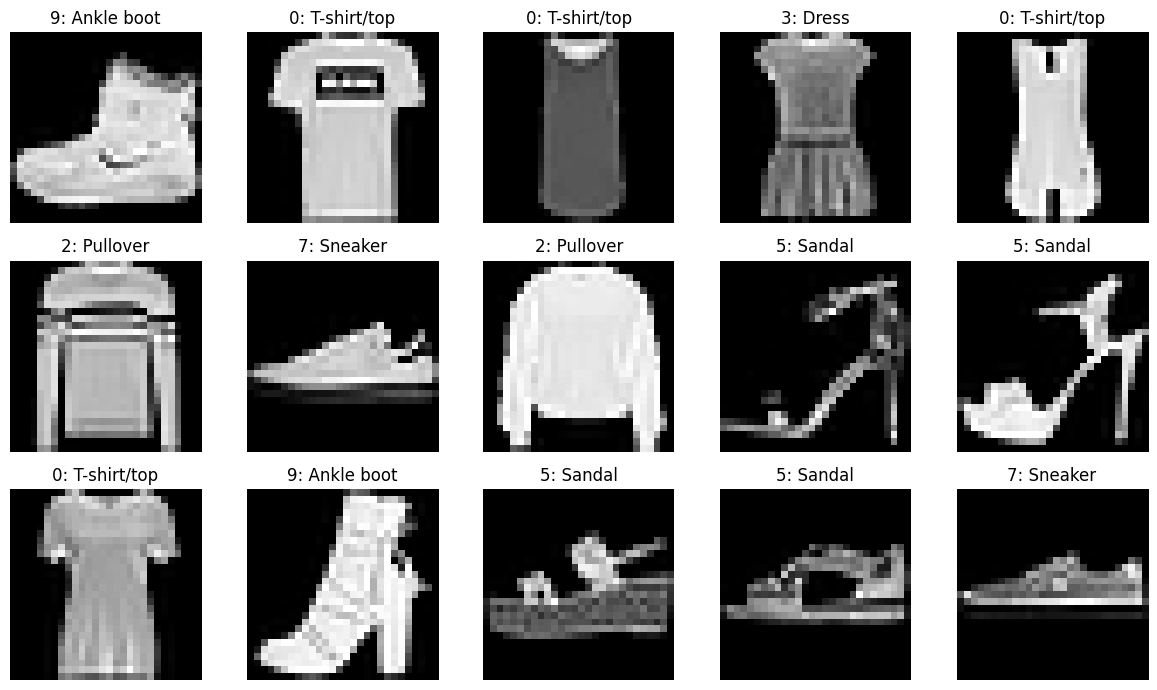

,class_id,class_name,count
0,0,T-shirt/top,6000
1,1,Trouser,6000
2,2,Pullover,6000
3,3,Dress,6000
4,4,Coat,6000
5,5,Sandal,6000
6,6,Shirt,6000
7,7,Sneaker,6000
8,8,Bag,6000
9,9,Ankle boot,6000


In [20]:
fig, axes = plt.subplots(3, 5, figsize=(12, 7))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train_full[i], cmap="gray")
    ax.set_title(f"{y_train_full[i]}: {class_names[y_train_full[i]]}")
    ax.axis("off")
plt.tight_layout(); plt.show()

unique, counts = np.unique(y_train_full, return_counts=True)
display(pd.DataFrame({"class_id": unique, "class_name": [class_names[i] for i in unique], "count": counts}))

## 2. Tách Train / Validation / Test và chuẩn hóa
- **Train**: cập nhật trọng số. **Validation**: chọn epoch và so sánh cấu hình. **Test**: chỉ để báo cáo kết quả cuối.
- Pixel được chia cho 255 để đưa về `[0, 1]`.

In [21]:
VAL_SIZE = 10_000
X_val, y_val = X_train_full[-VAL_SIZE:], y_train_full[-VAL_SIZE:]
X_train, y_train = X_train_full[:-VAL_SIZE], y_train_full[:-VAL_SIZE]

X_train = X_train.astype("float32") / 255.0
X_val   = X_val.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

print("Training  :", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test      :", X_test.shape, y_test.shape)
print("Min/max sau chuẩn hóa:", X_train.min(), X_train.max())

Training  : (50000, 28, 28) (50000,)
Validation: (10000, 28, 28) (10000,)
Test      : (10000, 28, 28) (10000,)
Min/max sau chuẩn hóa: 0.0 1.0


## 3. Hàm dựng mô hình và chạy một thí nghiệm
`run_experiment` thực hiện đủ quy trình **compile → train (EarlyStopping) → validate → evaluate** và trả về mọi số liệu cần cho báo cáo.
Mỗi thí nghiệm dùng cùng seed và cùng quy tắc dừng sớm, chỉ thay đổi yếu tố đang xét.

In [22]:
EPOCHS = 40

def make_ds(X, y, batch, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

def build_model(hidden=(256, 128), dropout=0.0, l2=0.0):
    reg = tf.keras.regularizers.l2(l2) if l2 > 0 else None
    layers = [tf.keras.layers.Input(shape=(28, 28)), tf.keras.layers.Flatten()]
    for i, units in enumerate(hidden):
        layers.append(tf.keras.layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout > 0 and i < len(hidden) - 1:          # Dropout giữa các tầng Dense ẩn
            layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(10, activation="softmax"))
    return tf.keras.Sequential(layers)

def run_experiment(name, hidden=(256, 128), lr=1e-3, batch=64, dropout=0.0, l2=0.0,
                   checkpoint=None, keep_model=False, verbose=0):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_model(hidden, dropout, l2)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(),
                  metrics=["accuracy"])

    callbacks = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]
    if checkpoint:
        callbacks.append(tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint, monitor="val_loss", save_best_only=True))

    train_ds = make_ds(X_train, y_train, batch, shuffle=True)
    val_ds, test_ds = make_ds(X_val, y_val, batch), make_ds(X_test, y_test, batch)

    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=verbose)
    train_time = time.time() - t0

    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    epochs_run = len(hist["loss"])
    best_epoch = int(np.argmin(hist["val_loss"])) + 1

    # sau EarlyStopping, mô hình đã được khôi phục về trọng số của epoch tốt nhất
    _, val_acc = model.evaluate(val_ds, verbose=0)
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    _, train_acc_inf = model.evaluate(X_train, y_train, batch_size=1024, verbose=0)  # chế độ suy luận

    res = dict(name=name, hidden=tuple(hidden), lr=lr, batch=batch, dropout=dropout, l2=l2,
               params=int(model.count_params()), hist=hist, best_epoch=best_epoch,
               train_time=train_time, sec_per_epoch=train_time / epochs_run,
               val_acc=float(val_acc), val_loss=float(min(hist["val_loss"])),
               test_acc=float(test_acc), test_loss=float(test_loss),
               gap=float(train_acc_inf - val_acc))
    if keep_model:
        res["model"] = model
    else:
        del model
    gc.collect()
    print(f"[{name}] epoch chạy {epochs_run}, tốt nhất {best_epoch} | "
          f"val {val_acc*100:.2f}% | test {test_acc*100:.2f}% | {train_time:.1f}s")
    return res

def summary_df(results):
    return pd.DataFrame([{
        "Cấu hình": r["name"], "Tham số": r["params"], "Epoch chạy": len(r["hist"]["loss"]),
        "Epoch tốt nhất": r["best_epoch"], "Train (s)": round(r["train_time"], 2),
        "s/epoch": round(r["sec_per_epoch"], 2), "Val loss": round(r["val_loss"], 4),
        "Val acc (%)": round(r["val_acc"] * 100, 2), "Test acc (%)": round(r["test_acc"] * 100, 2),
        "Chênh train/val (điểm %)": round(r["gap"] * 100, 2)} for r in results])

R = {}

## 4. Mô hình đối chứng (baseline)
Kiến trúc: `784 → 256 → 128 → 10`. Adam, learning rate `1e-3`, batch size `64`, EarlyStopping (patience 3) và ModelCheckpoint.

In [23]:
build_model().summary()
R["baseline"] = run_experiment("Đối chứng (256, 128)", hidden=(256, 128), lr=1e-3, batch=64,
                               checkpoint="best_mlp_fashion.keras", keep_model=True, verbose=1)
model = R["baseline"]["model"]

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8207 - loss: 0.5034 - val_accuracy: 0.8557 - val_loss: 0.4054
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8662 - loss: 0.3689 - val_accuracy: 0.8658 - val_loss: 0.3655
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8786 - loss: 0.3298 - val_accuracy: 0.8647 - val_loss: 0.3788
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8868 - loss: 0.3058 - val_accuracy: 0.8792 - val_loss: 0.3485
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8931 - loss: 0.2862 - val_accuracy: 0.8807 - val_loss: 0.3224
Epoch 6/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8993 - loss: 0.2710 - val_accuracy: 0.8849 - val_loss: 0.3174
Epoch 7/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9038 - loss: 0.2586 - val_accuracy: 0.8771 - val_loss: 0.3420
Epoch 8/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9052 - loss: 0.2502 - val_accuracy: 0

,accuracy,loss,val_accuracy,val_loss
7,0.90518,0.250220,0.8825,0.330180
8,0.90908,0.238160,0.8880,0.313794
9,0.91388,0.225890,0.8872,0.316668
10,0.91806,0.217152,0.8868,0.330894
11,0.91942,0.209739,0.8894,0.320706


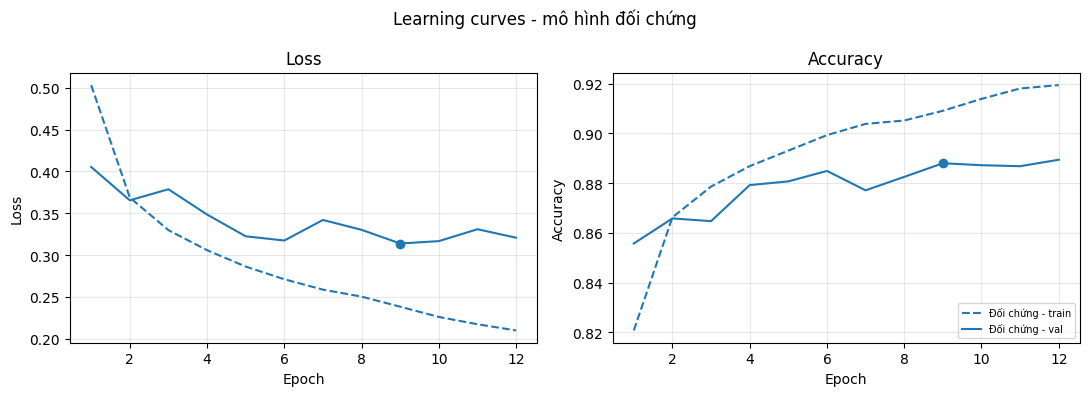

Epoch tốt nhất: 9 / 12


In [24]:
history_df = pd.DataFrame(R["baseline"]["hist"])
display(history_df.tail())

fig, _ = plot_compare([R["baseline"]], ["Đối chứng"], "Learning curves - mô hình đối chứng", "tmp_baseline_view.png")
plt.show()
print("Epoch tốt nhất:", R["baseline"]["best_epoch"], "/", len(history_df))

## 5. Đánh giá trên Test set, Confusion Matrix, Classification Report

Test loss     : 0.3289
Test accuracy : 0.8855
Probability shape: (10000, 10)


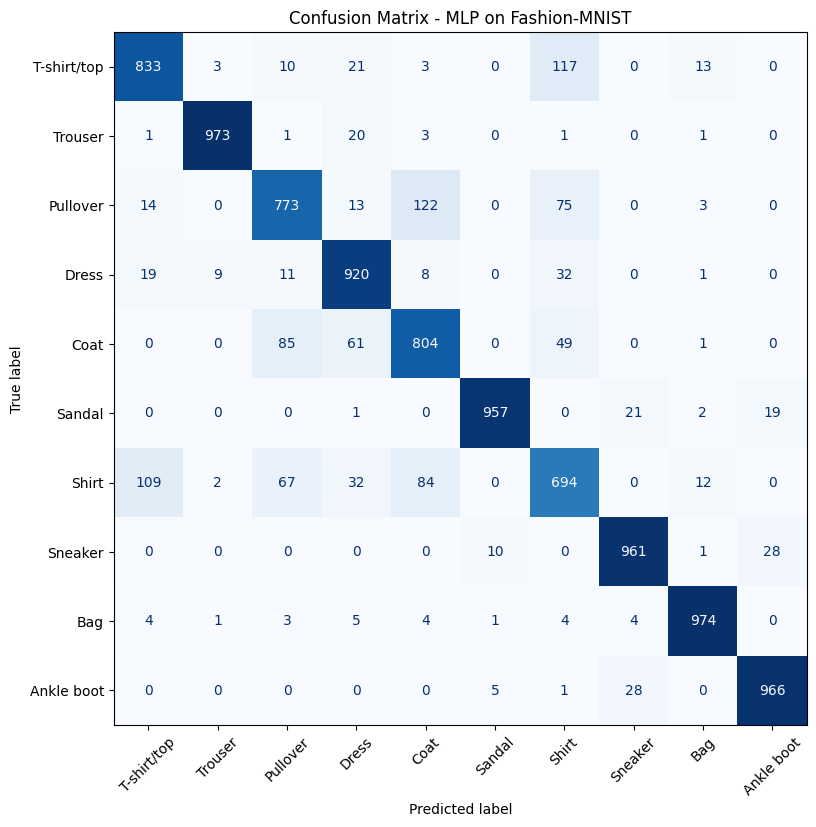

              precision    recall  f1-score   support

 T-shirt/top     0.8500    0.8330    0.8414      1000
     Trouser     0.9848    0.9730    0.9789      1000
    Pullover     0.8137    0.7730    0.7928      1000
       Dress     0.8574    0.9200    0.8876      1000
        Coat     0.7821    0.8040    0.7929      1000
      Sandal     0.9836    0.9570    0.9701      1000
       Shirt     0.7133    0.6940    0.7035      1000
     Sneaker     0.9477    0.9610    0.9543      1000
         Bag     0.9663    0.9740    0.9701      1000
  Ankle boot     0.9536    0.9660    0.9598      1000

    accuracy                         0.8855     10000
   macro avg     0.8852    0.8855    0.8851     10000
weighted avg     0.8852    0.8855    0.8851     10000

Hai cặp lớp bị nhầm nhiều nhất (tính cả hai chiều):
  T-shirt/top và Shirt: 226 ảnh
  Pullover và Coat: 207 ảnh


In [25]:
base = R["baseline"]
print(f"Test loss     : {base['test_loss']:.4f}")
print(f"Test accuracy : {base['test_acc']:.4f}")

y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
pred_conf = y_prob[np.arange(len(y_pred)), y_pred]
print("Probability shape:", y_prob.shape)

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix - MLP on Fashion-MNIST"); plt.show()

print(classification_report(y_test, y_pred, target_names=class_names, digits=4))
report_dict = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)

print("Hai cặp lớp bị nhầm nhiều nhất (tính cả hai chiều):")
for n, a, c in confused_pairs(cm, class_names, 2):
    print(f"  {a} và {c}: {n} ảnh")

## 6. Trực quan hóa dự đoán, inference một ảnh, lưu và khôi phục mô hình

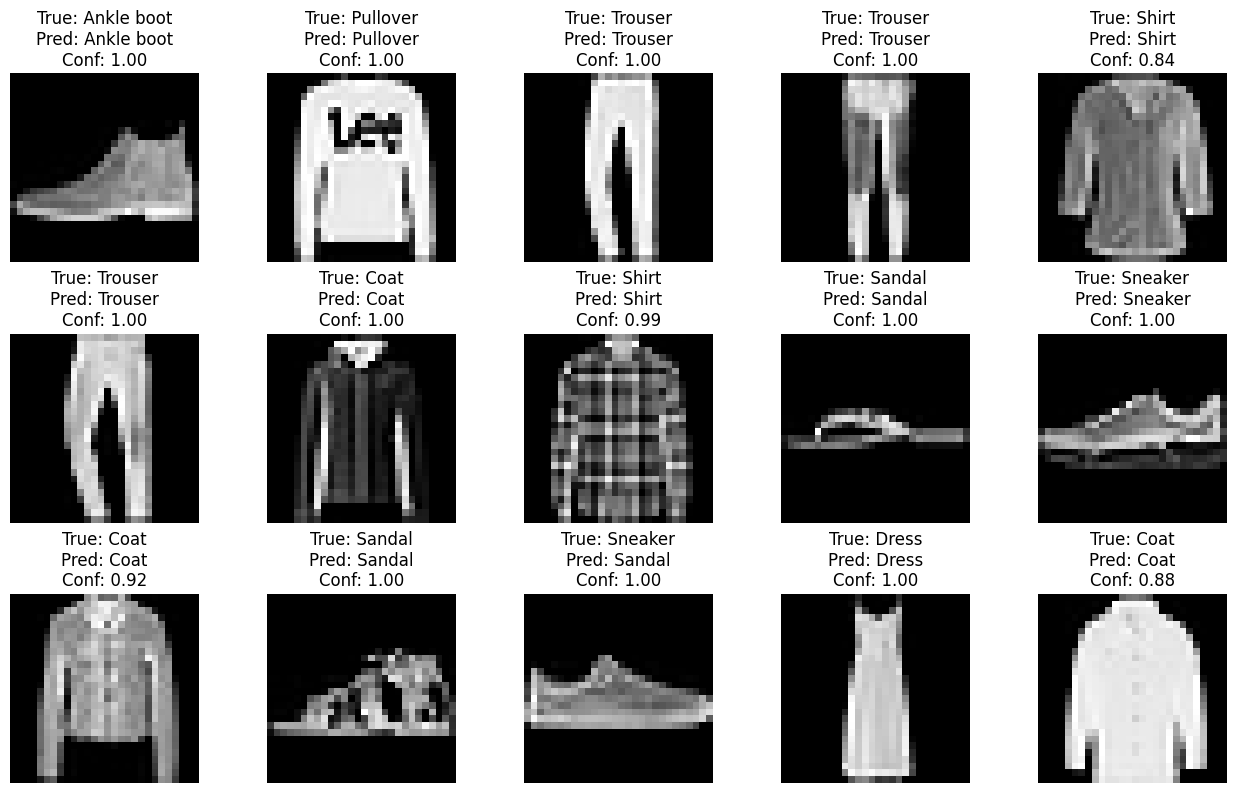

True label : Ankle boot
Prediction : Ankle boot
Confidence : 0.9970600008964539
Loaded model test accuracy: 0.8855


In [26]:
fig, axes = plt.subplots(3, 5, figsize=(13, 8))
for idx, ax in zip(np.arange(15), axes.ravel()):
    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}\nConf: {pred_conf[idx]:.2f}")
    ax.axis("off")
plt.tight_layout(); plt.show()

# Inference trên một ảnh riêng lẻ
sample_prob = model.predict(X_test[0][None, ...], verbose=0)[0]
sample_pred = int(np.argmax(sample_prob))
print("True label :", class_names[y_test[0]])
print("Prediction :", class_names[sample_pred])
print("Confidence :", float(sample_prob[sample_pred]))

# Lưu và khôi phục mô hình
final_model_path = "fashion_mnist_mlp_final.keras"
model.save(final_model_path)
loaded_model = tf.keras.models.load_model(final_model_path)
_, loaded_acc = loaded_model.evaluate(make_ds(X_test, y_test, 64), verbose=0)
print("Loaded model test accuracy:", round(float(loaded_acc), 4))

# Các bài mở rộng
Mỗi bài chỉ thay đổi yếu tố đang xét, các yếu tố khác giữ như mô hình đối chứng. Việc chọn cấu hình tốt hơn dựa trên **validation**, không dựa trên test.

## Bài 1. Thay đổi số tầng ẩn (1, 2, 3 tầng)

In [27]:
arch_cfgs = [(256,), (256, 128), (256, 128, 64)]
R["arch"] = []
for hcfg in arch_cfgs:
    if hcfg == (256, 128):
        R["arch"].append(R["baseline"])          # dùng lại kết quả đối chứng
    else:
        R["arch"].append(run_experiment(f"{len(hcfg)} tầng ẩn {hcfg}", hidden=hcfg))
display(summary_df(R["arch"]))

[1 tầng ẩn (256,)] epoch chạy 12, tốt nhất 9 | val 88.67% | test 88.29% | 30.9s
[3 tầng ẩn (256, 128, 64)] epoch chạy 12, tốt nhất 9 | val 88.93% | test 88.42% | 36.1s


,Cấu hình,Tham số,Epoch chạy,Epoch tốt nhất,Train (s),s/epoch,Val loss,Val acc (%),Test acc (%),Chênh train/val (điểm %)
0,"1 tầng ẩn (256,)",203530,12,9,30.93,2.58,0.3125,88.67,88.29,3.10
1,"Đối chứng (256, 128)",235146,12,9,49.77,4.15,0.3138,88.80,88.55,3.35
2,"3 tầng ẩn (256, 128, 64)",242762,12,9,36.10,3.01,0.3144,88.93,88.42,2.95


## Bài 2. Thay đổi learning rate (1e-2, 1e-3, 1e-4)

[lr = 0.01] epoch chạy 9, tốt nhất 6 | val 86.38% | test 85.99% | 26.0s
[lr = 0.0001] epoch chạy 22, tốt nhất 19 | val 88.81% | test 88.14% | 67.2s


,Cấu hình,Tham số,Epoch chạy,Epoch tốt nhất,Train (s),s/epoch,Val loss,Val acc (%),Test acc (%),Chênh train/val (điểm %)
0,lr = 0.01,235146,9,6,26.03,2.89,0.3773,86.38,85.99,1.40
1,"Đối chứng (256, 128)",235146,12,9,49.77,4.15,0.3138,88.80,88.55,3.35
2,lr = 0.0001,235146,22,19,67.16,3.05,0.3119,88.81,88.14,2.89


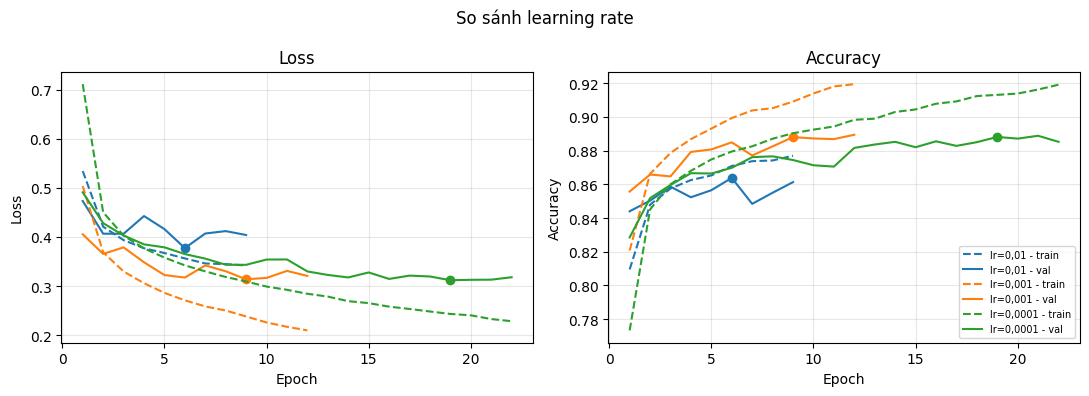

In [28]:
R["lr"] = []
for lr in [1e-2, 1e-3, 1e-4]:
    if lr == 1e-3:
        R["lr"].append(R["baseline"])
    else:
        R["lr"].append(run_experiment(f"lr = {lr:g}", lr=lr))
display(summary_df(R["lr"]))
fig, _ = plot_compare(R["lr"], [f"lr={lrs(r['lr'])}" for r in R["lr"]], "So sánh learning rate", "tmp_lr_view.png")
plt.show()

## Bài 3. Thay đổi batch size (32, 128, 512)

In [29]:
R["bs"] = [run_experiment(f"batch = {b}", batch=b) for b in [32, 128, 512]]
display(summary_df(R["bs"]))

[batch = 32] epoch chạy 12, tốt nhất 9 | val 89.14% | test 88.55% | 56.9s
[batch = 128] epoch chạy 12, tốt nhất 9 | val 88.71% | test 88.05% | 24.5s
[batch = 512] epoch chạy 17, tốt nhất 14 | val 88.94% | test 88.90% | 20.3s


,Cấu hình,Tham số,Epoch chạy,Epoch tốt nhất,Train (s),s/epoch,Val loss,Val acc (%),Test acc (%),Chênh train/val (điểm %)
0,batch = 32,235146,12,9,56.85,4.74,0.3056,89.14,88.55,2.96
1,batch = 128,235146,12,9,24.53,2.04,0.3179,88.71,88.05,2.99
2,batch = 512,235146,17,14,20.27,1.19,0.3021,88.94,88.90,3.84


## Bài 4 và Bài 5. Thêm Dropout(0.3) và L2(1e-4)

[Dropout 0,3] epoch chạy 22, tốt nhất 19 | val 89.41% | test 88.86% | 73.1s
[L2 0,0001] epoch chạy 12, tốt nhất 9 | val 88.85% | test 88.02% | 40.1s


,Cấu hình,Tham số,Epoch chạy,Epoch tốt nhất,Train (s),s/epoch,Val loss,Val acc (%),Test acc (%),Chênh train/val (điểm %)
0,"Đối chứng (256, 128)",235146,12,9,49.77,4.15,0.3138,88.80,88.55,3.35
1,"Dropout 0,3",235146,22,19,73.12,3.32,0.2976,89.41,88.86,3.20
2,"L2 0,0001",235146,12,9,40.11,3.34,0.3667,88.85,88.02,2.41


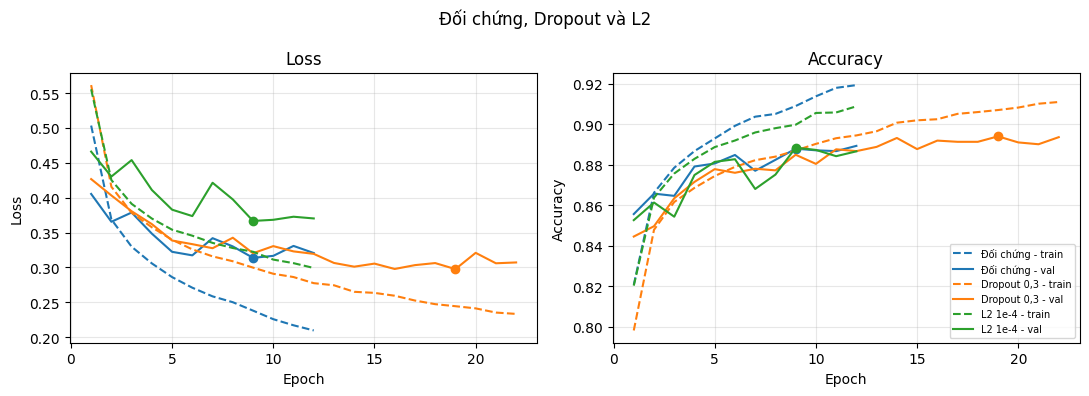

In [30]:
R["dropout"] = run_experiment("Dropout 0,3", dropout=0.3)
R["l2"]      = run_experiment("L2 0,0001", l2=1e-4)
display(summary_df([R["baseline"], R["dropout"], R["l2"]]))
fig, _ = plot_compare([R["baseline"], R["dropout"], R["l2"]], ["Đối chứng", "Dropout 0,3", "L2 1e-4"],
                      "Đối chứng, Dropout và L2", "tmp_reg_view.png")
plt.show()

## Bài 6. 20 ảnh dự đoán sai có confidence cao nhất (mô hình đối chứng)

Số mẫu dự đoán sai: 1145


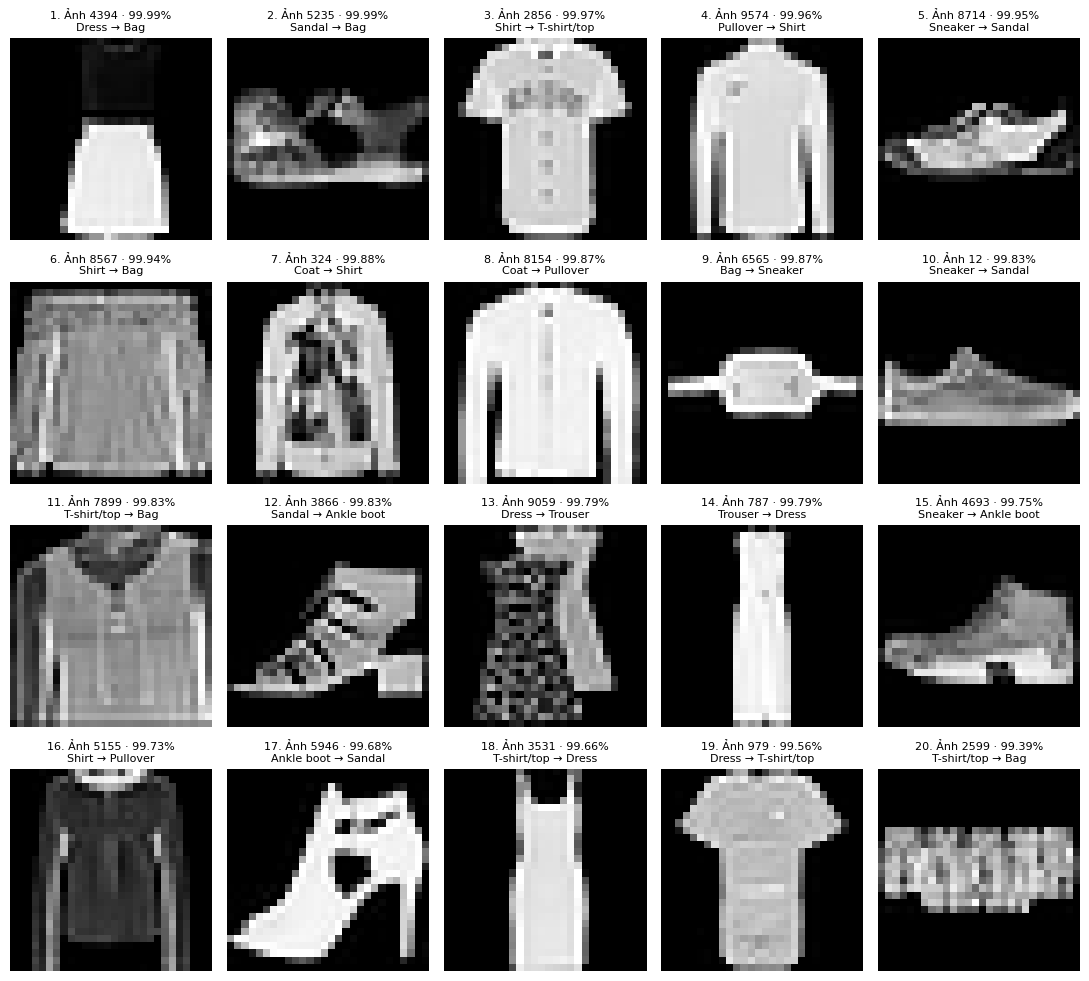

,Ảnh,Nhãn thật,Dự đoán,Confidence (%)
0,4394,Dress,Bag,99.989998
1,5235,Sandal,Bag,99.989998
2,2856,Shirt,T-shirt/top,99.970001
3,9574,Pullover,Shirt,99.959999
4,8714,Sneaker,Sandal,99.949997
5,8567,Shirt,Bag,99.940002
6,324,Coat,Shirt,99.879997
7,8154,Coat,Pullover,99.870003
8,6565,Bag,Sneaker,99.870003
9,12,Sneaker,Sandal,99.830002


In [31]:
wrong = np.where(y_pred != y_test)[0]
top20 = wrong[np.argsort(-pred_conf[wrong])][:20]
print("Số mẫu dự đoán sai:", len(wrong))

fig, _ = plot_top_errors(top20, X_test, y_test, y_pred, pred_conf, class_names, "tmp_top20_view.png")
plt.show()

display(pd.DataFrame({
    "Ảnh": top20, "Nhãn thật": [class_names[y_test[i]] for i in top20],
    "Dự đoán": [class_names[y_pred[i]] for i in top20],
    "Confidence (%)": [round(pred_conf[i] * 100, 2) for i in top20]}))